# The collapse-boundary law across teachers and student inits — the `law-*` campaign

**Question.** Notebook §11–§12 of `cross_model_student_hp_exploration.ipynb` found that an ep20
student *collapses* — loses the trait entirely, not just weakly — when

$$K \;=\; \mathrm{lr}\cdot \alpha^{\,b}\cdot r^{\,c} \;\ge\; K^{\ast}$$

with $b \approx 0.58$ and $c \approx -0.09$ (rank is **protective**). But that was fit on a
**single lineage**: teacher `ep2_lr5e-4_r32a64` → student `data-seed1`, ep20 only. Is the law a
property of distillation, or of that one teacher/student pair?

**The campaign.** Six arms — three teacher recipes × two student inits — each a ~110-cell grid over
rank $\{1,2,4,8,16,32,64\}$ × $\alpha\,\{1\ldots128\}$ × lr $\{2\!\times\!10^{-5}\ldots5\!\times\!10^{-3}\}$
at student ep20, 3 seeds per cell (5 on the original lineage). Queues `law-exp`, `law-focus5`,
`law-{strong,weak}-ds1`, `law-{focus,strong,weak}-ws1`; **554 jobs, all `rc=0`**, completed
2026-07-27 14:43 UTC.

| family | teacher recipe | character |
|---|---|---|
| `focus` | `ep2_lr5e-4_r32a64` | short, aggressive — the §11–§12 lineage |
| `strong` | `ep2_lr5e-4_r16a64` | short, aggressive, lower rank |
| `weak` | `ep7_lr1e-4_r16a32` | long, gentle |

Student inits: `pythia-160m-data-seed1` (different data order) and `pythia-160m-weight-seed1`
(different initial weights).

---

## Headline findings

1. **The law generalises.** At a collapse threshold that respects every lineage's score
   distribution, all six arms agree: $b \in [0.53, 0.58]$ (pooled **0.561**, $I^2=2\%$, $p=0.40$)
   and $c \in [-0.13, -0.07]$ (pooled **−0.085**, $I^2=0\%$, $p=0.82$). $K^{\ast}$ spans only
   **1.4×** across arms. The law misses 3–8 of ~110 cells per arm.
2. **Rank is in the law everywhere.** $c<0$ with an interval excluding zero in **all six** arms.
   Model-free confirmation: at matched $(\mathrm{lr},\alpha)$, rank-1/2 cells collapse 67% of the
   time vs 29% for rank ≥8 — 14/19 slices favour high rank, **zero reverse** (Wilcoxon $p=0.001$).
3. **§12's threshold does not transfer — and this matters.** The inherited `DEAD_SEED = 0.01` was
   tuned on the focus lineage, whose live mode sits at 0.02–0.1. The weaker arms' live modes sit at
   0.01–0.02, so 0.01 cuts *through* them. Using it manufactures apparent heterogeneity
   ($I^2=75\%/78\%$) and a spurious **6.3×** spread in $K^{\ast}$ that both vanish at 0.005. §3 below.
4. **Signal still peaks just below the cliff**, on every arm — mean $p_{dog}$ among survivors rises
   through $K/K^{\ast}\to1$ and falls past it. The operating rule *"ride just under the boundary"*
   transfers even though the boundary's absolute location must be re-measured per lineage.
5. **The standard recipe is leaving 2–4× on the table** on four of six arms, and on the `weak`
   arms it sits close enough to the cliff that a gentler cell beats it outright.

## Setup

In [1]:
from __future__ import annotations

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2, wilcoxon

from subliminal_learning.analysis import collapse_law as cl
from subliminal_learning.analysis.setup import bootstrap, set_plot_style

warnings.filterwarnings("ignore")          # statsmodels separation chatter on a near-separable design
pd.set_option("display.width", 200)
set_plot_style(dpi=115, hide_spines=True)

ROOT, OUTPUT_ROOT = bootstrap()
LIN = cl.LINEAGE_ORDER
SHORT = {l: f"{l.split(':')[0]}:{l.split(':')[1].replace('-seed1', '')[:6]}" for l in LIN}
COLOR = dict(zip(LIN, plt.rcParams["axes.prop_cycle"].by_key()["color"]))
# data-seed arms solid, weight-seed arms dashed -- the init axis is the one worth reading off a line
STYLE = {l: ("-" if l.endswith("data-seed1") else "--") for l in LIN}

cells, runs_raw = cl.load_law_runs(OUTPUT_ROOT)
print(f"{len(cells)} ep20 cells / {len(runs_raw)} seed-runs across {cells.lineage.nunique()} lineages")
print(f"output_root: {OUTPUT_ROOT}")

681 ep20 cells / 2305 seed-runs across 6 lineages
output_root: /mnt/ssd-2/soar-subliminal/angela/outputs


## 1. Inventory — what the campaign actually produced

The rank-1/2 cells matter disproportionately: §12's original grid never ran rank below 4, and that
blind spot is what made the rank exponent look insignificant. A late add-on (5 jobs per queue)
patched rank 1 and 2 into **every** arm, so each one can now identify $c$ on its own.

In [2]:
inv = (cells.groupby(["family", "base_label"])
       .agg(cells=("student_tag", "nunique"), seed_runs=("n_seeds", "sum"),
            min_seeds=("n_seeds", "min"), max_seeds=("n_seeds", "max")))
display(inv)

print("\ncells per rank (the rank-1/2 columns are the add-on that identifies c):")
display(pd.crosstab(cells.lineage, cells["rank"]).reindex(LIN))

grid = cells[cells.lineage.eq("weak:data-seed1")]
print("grid axes (weak:data-seed1, representative):")
print("  lr    :", [f"{v:g}" for v in sorted(grid.lr.unique())])
print("  rank  :", [int(v) for v in sorted(grid["rank"].unique())])
print("  alpha :", [int(v) for v in sorted(grid.alpha.unique())])

cells  seed_runs  min_seeds  max_seeds
family base_label                                          
focus  data-seed1      131        655          5          5
       weight-seed1    110        330          3          3
strong data-seed1      110        330          3          3
       weight-seed1    110        330          3          3
weak   data-seed1      110        330          3          3
       weight-seed1    110        330          3          3


cells per rank (the rank-1/2 columns are the add-on that identifies c):


rank,1,2,4,8,16,32,64
lineage,,,,,,,
focus:data-seed1,4,4,20,49,25,14,15
focus:weight-seed1,3,2,19,45,23,13,5
strong:data-seed1,3,2,19,45,23,13,5
strong:weight-seed1,3,2,19,45,23,13,5
weak:data-seed1,3,2,19,45,23,13,5
weak:weight-seed1,3,2,19,45,23,13,5


grid axes (weak:data-seed1, representative):
  lr    : ['2e-05', '5e-05', '0.0001', '0.0002', '0.0003', '0.0004', '0.0005', '0.0008', '0.001', '0.005']
  rank  : [1, 2, 4, 8, 16, 32, 64]
  alpha : [1, 2, 4, 8, 16, 32, 64, 128]


## 2. Where is "collapsed"? — the threshold cannot be inherited

Collapse is a *bimodal* phenomenon: a seed either keeps some trait signal or its answer
distribution is destroyed and $p_{dog}$ falls orders of magnitude below any base rate. The binary
label needs a cut in the empty trough between the two modes.

§12 used `DEAD_SEED = 0.01`, chosen on the focus lineage. The histogram below shows why that number
is **lineage-specific**: the focus arm's live mode sits at 0.02–0.1, leaving 0.01 comfortably in
the trough — but the weaker arms transfer far less signal, and their live modes sit at 0.01–0.02.
On `weak:weight-seed1`, 109 of 330 runs land in the 0.01–0.02 bin, i.e. right where the inherited
threshold cuts.

lineage,focus:data-seed1,focus:weight-seed1,strong:data-seed1,strong:weight-seed1,weak:data-seed1,weak:weight-seed1
bin,,,,,,
<1e-6,141,86,76,102,72,59
1e-6..1e-5,41,23,18,19,7,15
1e-5..1e-4,32,15,18,8,15,14
1e-4..1e-3,34,13,12,12,15,24
1e-3..5e-3,20,12,14,14,28,24
5e-3..1e-2,14,11,12,13,21,72
1e-2..2e-2,15,72,30,90,110,109
2e-2..5e-2,155,74,123,61,58,13
5e-2..0.1,114,17,22,9,4,0


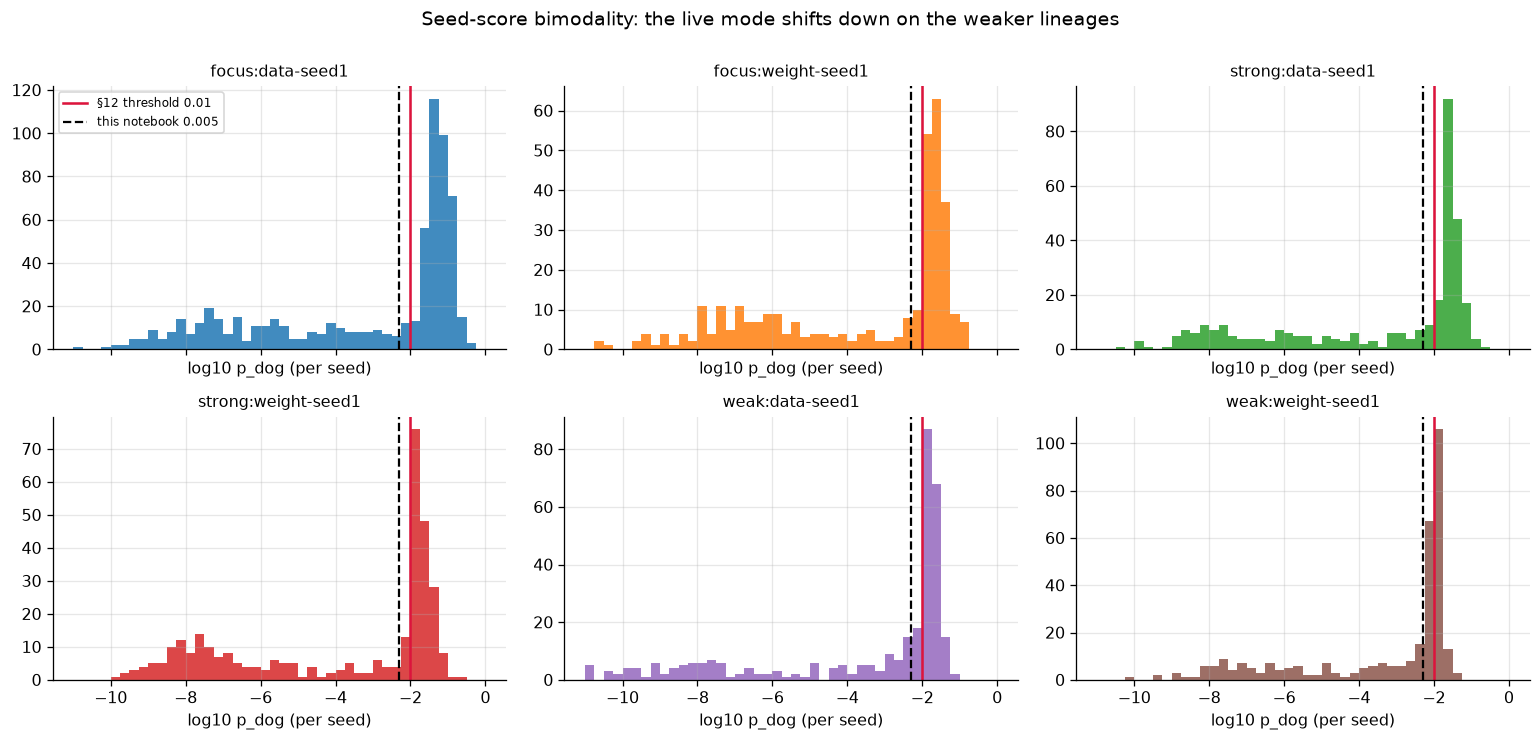

In [3]:
EDGES = [0, 1e-6, 1e-5, 1e-4, 1e-3, 5e-3, 1e-2, 2e-2, 5e-2, 1e-1, 1.0]
LABS = ["<1e-6", "1e-6..1e-5", "1e-5..1e-4", "1e-4..1e-3", "1e-3..5e-3",
        "5e-3..1e-2", "1e-2..2e-2", "2e-2..5e-2", "5e-2..0.1", ">0.1"]
hist = (runs_raw.assign(bin=pd.cut(runs_raw.test, EDGES, labels=LABS, include_lowest=True))
        .pivot_table(index="bin", columns="lineage", values="test", aggfunc="count", observed=False)
        .reindex(columns=LIN).fillna(0).astype(int))
display(hist)

fig, axes = plt.subplots(2, 3, figsize=(13.5, 6.4), sharex=True)
for ax, lin in zip(axes.ravel(), LIN):
    v = np.log10(np.clip(runs_raw[runs_raw.lineage.eq(lin)].test, 1e-11, None))
    ax.hist(v, bins=np.linspace(-11, 0, 45), color=COLOR[lin], alpha=.85)
    ax.axvline(np.log10(0.01), color="crimson", lw=1.6, label="§12 threshold 0.01")
    ax.axvline(np.log10(0.005), color="k", lw=1.4, ls="--", label="this notebook 0.005")
    ax.set_title(lin, fontsize=10)
    ax.set_xlabel("log10 p_dog (per seed)")
axes[0, 0].legend(fontsize=7.5, loc="upper left")
fig.suptitle("Seed-score bimodality: the live mode shifts down on the weaker lineages", y=1.0)
fig.tight_layout(); plt.show()

**Consequence.** `0.005` sits in the trough for all six arms, so it is used throughout below.
§8 shows the full sensitivity curve: every threshold from $5\times10^{-4}$ to $5\times10^{-3}$
gives the same answer, and only at 0.01 and above — where the cut enters the weaker arms' live
mode — do the estimates break up.

In [4]:
DEAD = 0.005
runs = cl.label_collapse(runs_raw, dead_seed=DEAD)
print(f"threshold {DEAD}: {runs.collapsed.sum()} / {len(runs)} seed-runs labelled collapsed "
      f"({runs.collapsed.mean():.1%})")
print(runs.groupby("lineage").collapsed.mean().reindex(LIN).round(3).to_string())

threshold 0.005: 983 / 2305 seed-runs labelled collapsed (42.6%)
lineage
focus:data-seed1       0.409
focus:weight-seed1     0.452
strong:data-seed1      0.418
strong:weight-seed1    0.470
weak:data-seed1        0.415
weak:weight-seed1      0.412


## 3. The fit — one law for all six lineages

$$\mathrm{logit}\,P(\text{collapse}) = \beta_0 + \beta_{lr}\ln \mathrm{lr} + \beta_\alpha\ln\alpha + \beta_r\ln r,
\qquad b=\beta_\alpha/\beta_{lr},\quad c=\beta_r/\beta_{lr}$$

Two properties of this design drive the estimator, both handled in
`subliminal_learning.analysis.collapse_law`:

- **Near-separability.** Collapse is nearly a deterministic function of $K$, so coefficient
  *magnitudes* are only pinned down by the penalty — but the *ratios* $b$ and $c$ are identified.
  We report ratios only.
- **Seeds within a cell are correlated.** Resampling seeds independently would manufacture
  significance. Both inference paths cluster on the cell: a cluster-robust covariance
  (statsmodels) propagated to the ratios by the delta method, cross-checked against a
  cell-clustered bootstrap with a ridge fit (scikit-learn, matching §12's `pen=1e-3` objective to
  7 decimals).

In [5]:
fits, ks_all, rows = {}, {}, []
for lin in LIN:
    d = runs[runs.lineage.eq(lin)]
    f = cl.fit_collapse_law(d)
    _, bci, cci = cl.cluster_bootstrap_ratios(d, n_boot=600)
    ks = cl.estimate_kstar(d, f.b, f.c)
    n_miss, n_cell = cl.law_misses(d, f.b, f.c, ks["kstar"])
    fits[lin], ks_all[lin] = f, ks
    rows.append(dict(lineage=lin, cells=f.n_cells, runs=f.n_runs, dead=round(f.dead_frac, 3),
                     b=round(f.b, 3), b_delta=f"[{f.b_ci[0]:+.2f}, {f.b_ci[1]:+.2f}]",
                     b_boot=f"[{bci[0]:+.2f}, {bci[1]:+.2f}]",
                     c=round(f.c, 3), c_delta=f"[{f.c_ci[0]:+.2f}, {f.c_ci[1]:+.2f}]",
                     c_boot=f"[{cci[0]:+.2f}, {cci[1]:+.2f}]",
                     c_excl_0="YES" if f.c_excludes_zero else "no",
                     Kstar=f"{ks['kstar']:.2e}", law_misses=f"{n_miss}/{n_cell}"))
summary = pd.DataFrame(rows)
display(summary)
print("delta = cluster-robust delta method; boot = 600-replicate cell-clustered bootstrap")

,lineage,cells,runs,dead,b,b_delta,b_boot,c,c_delta,c_boot,c_excl_0,Kstar,law_misses
0,focus:data-seed1,131,655,0.409,0.568,"[+0.55, +0.59]","[+0.55, +0.59]",-0.082,"[-0.10, -0.06]","[-0.11, -0.06]",YES,8.91e-04,3/131
1,focus:weight-seed1,110,330,0.452,0.564,"[+0.52, +0.60]","[+0.52, +0.61]",-0.081,"[-0.12, -0.05]","[-0.13, -0.04]",YES,7.79e-04,3/110
2,strong:data-seed1,110,330,0.418,0.545,"[+0.51, +0.58]","[+0.49, +0.58]",-0.068,"[-0.12, -0.01]","[-0.14, -0.02]",YES,7.94e-04,4/110
3,strong:weight-seed1,110,330,0.470,0.541,"[+0.51, +0.57]","[+0.51, +0.58]",-0.093,"[-0.14, -0.05]","[-0.13, -0.04]",YES,6.60e-04,3/110
4,weak:data-seed1,110,330,0.415,0.581,"[+0.54, +0.62]","[+0.54, +0.63]",-0.127,"[-0.20, -0.05]","[-0.23, -0.08]",YES,6.66e-04,8/110
5,weak:weight-seed1,110,330,0.412,0.530,"[+0.48, +0.58]","[+0.46, +0.58]",-0.103,"[-0.17, -0.04]","[-0.19, -0.04]",YES,6.35e-04,7/110


delta = cluster-robust delta method; boot = 600-replicate cell-clustered bootstrap


In [6]:
def homogeneity(values, cis, name, claim=None):
    '''Inverse-variance pooling + Cochran's Q across the six lineage estimates.'''
    se = (cis[:, 1] - cis[:, 0]) / (2 * 1.96)
    w = 1 / se ** 2
    pooled = (values * w).sum() / w.sum()
    Q = (w * (values - pooled) ** 2).sum()
    p = 1 - chi2.cdf(Q, len(values) - 1)
    I2 = max(0.0, (Q - (len(values) - 1)) / Q) * 100
    print(f"{name}: pooled = {pooled:+.3f}   spread [{values.min():+.3f}, {values.max():+.3f}]")
    print(f"    Cochran Q = {Q:.1f} (df={len(values)-1}), p = {p:.2g}, I^2 = {I2:.0f}%"
          f"  ->  {'HETEROGENEOUS' if p < 0.05 else 'consistent across lineages'}")
    if claim is not None:
        print(f"    §12 single-lineage value: {claim}")
    return pooled

b_vals = np.array([fits[l].b for l in LIN]); b_cis = np.array([fits[l].b_ci for l in LIN])
c_vals = np.array([fits[l].c for l in LIN]); c_cis = np.array([fits[l].c_ci for l in LIN])
pooled_b = homogeneity(b_vals, b_cis, "b (alpha exponent)", "0.58 [0.56, 0.61]")
print()
pooled_c = homogeneity(c_vals, c_cis, "c (rank exponent) ", "-0.093 [-0.138, -0.065]")
print(f"\nc excludes zero in {sum(fits[l].c_excludes_zero for l in LIN)}/6 lineages"
      f"  ->  rank is in the law on every teacher recipe and both student inits")

b (alpha exponent): pooled = +0.561   spread [+0.530, +0.581]
    Cochran Q = 5.1 (df=5), p = 0.4, I^2 = 2%  ->  consistent across lineages
    §12 single-lineage value: 0.58 [0.56, 0.61]

c (rank exponent) : pooled = -0.085   spread [-0.127, -0.068]
    Cochran Q = 2.2 (df=5), p = 0.82, I^2 = 0%  ->  consistent across lineages
    §12 single-lineage value: -0.093 [-0.138, -0.065]

c excludes zero in 6/6 lineages  ->  rank is in the law on every teacher recipe and both student inits


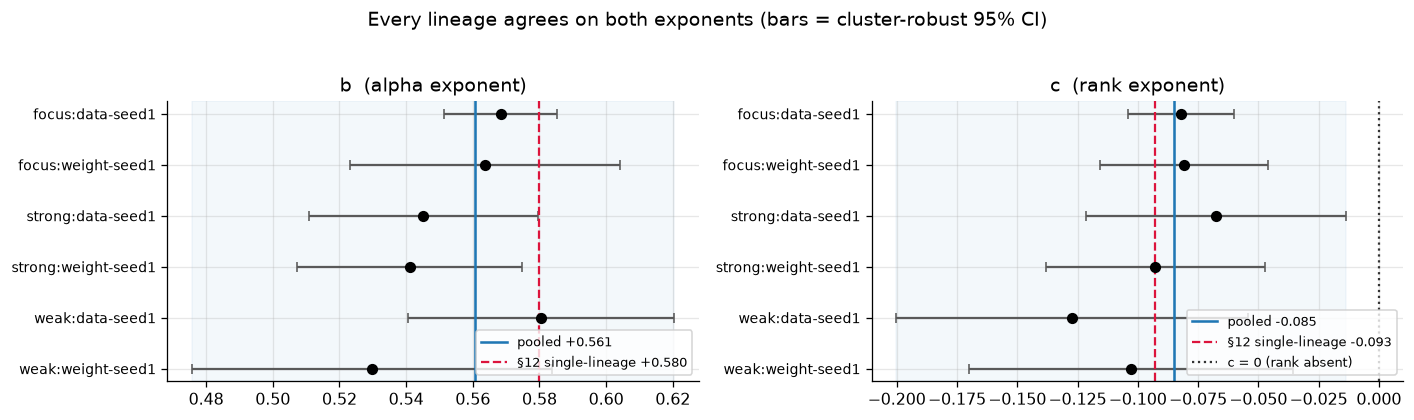

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12.4, 3.5))
for ax, vals, cis, pooled, name, ref in [
        (axes[0], b_vals, b_cis, pooled_b, "b  (alpha exponent)", 0.58),
        (axes[1], c_vals, c_cis, pooled_c, "c  (rank exponent)", -0.093)]:
    y = np.arange(len(LIN))[::-1]
    ax.errorbar(vals, y, xerr=[vals - cis[:, 0], cis[:, 1] - vals], fmt="o", ms=6,
                color="k", ecolor="0.35", capsize=3, lw=1.4)
    ax.axvline(pooled, color="tab:blue", lw=1.6, label=f"pooled {pooled:+.3f}")
    ax.axvspan(cis[:, 0].min(), cis[:, 1].max(), color="tab:blue", alpha=.05)
    ax.axvline(ref, color="crimson", ls="--", lw=1.4, label=f"§12 single-lineage {ref:+.3f}")
    if name.startswith("c"):
        ax.axvline(0, color="0.2", ls=":", lw=1.4, label="c = 0 (rank absent)")
    ax.set_yticks(y); ax.set_yticklabels(LIN, fontsize=9)
    ax.set_title(name); ax.legend(fontsize=8, loc="lower right")
fig.suptitle("Every lineage agrees on both exponents (bars = cluster-robust 95% CI)", y=1.03)
fig.tight_layout(); plt.show()

## 4. $K^{\ast}$ — the boundary's location

The exponents say what trades off against what; $K^{\ast}$ says *where* the cliff is. It is estimated
as the geometric mean of the $K$ of the **mixed** cells (those that lose some but not all seeds) —
the boundary is stochastic, not a hard edge.

In [8]:
kt = pd.DataFrame([{"family": l.split(":")[0], "base": l.split(":")[1],
                    "Kstar": ks_all[l]["kstar"], "n_mixed": ks_all[l]["n_mixed"],
                    "band_lo": ks_all[l]["band"][0], "band_hi": ks_all[l]["band"][1]} for l in LIN])
piv = kt.pivot(index="family", columns="base", values="Kstar").reindex(["focus", "strong", "weak"])
print("K* by teacher family x student init:")
display(piv.style.format("{:.2e}"))
print(f"spread across all six arms: {kt.Kstar.max() / kt.Kstar.min():.2f}x")
print("weight-seed1 / data-seed1 ratio: "
      + ", ".join(f"{f} = {r:.2f}" for f, r in (piv['weight-seed1'] / piv['data-seed1']).items()))
print("\n(ordering is consistent -- focus > strong > weak, and weight-seed1 <= data-seed1 --")
print(" but the whole range is 1.4x, i.e. small next to the 250x span of lr in the grid.)")

K* by teacher family x student init:


base,data-seed1,weight-seed1
family,,
focus,8.91e-04,7.79e-04
strong,7.94e-04,6.60e-04
weak,6.66e-04,6.35e-04


spread across all six arms: 1.40x
weight-seed1 / data-seed1 ratio: focus = 0.87, strong = 0.83, weak = 0.95

(ordering is consistent -- focus > strong > weak, and weight-seed1 <= data-seed1 --
 but the whole range is 1.4x, i.e. small next to the 250x span of lr in the grid.)


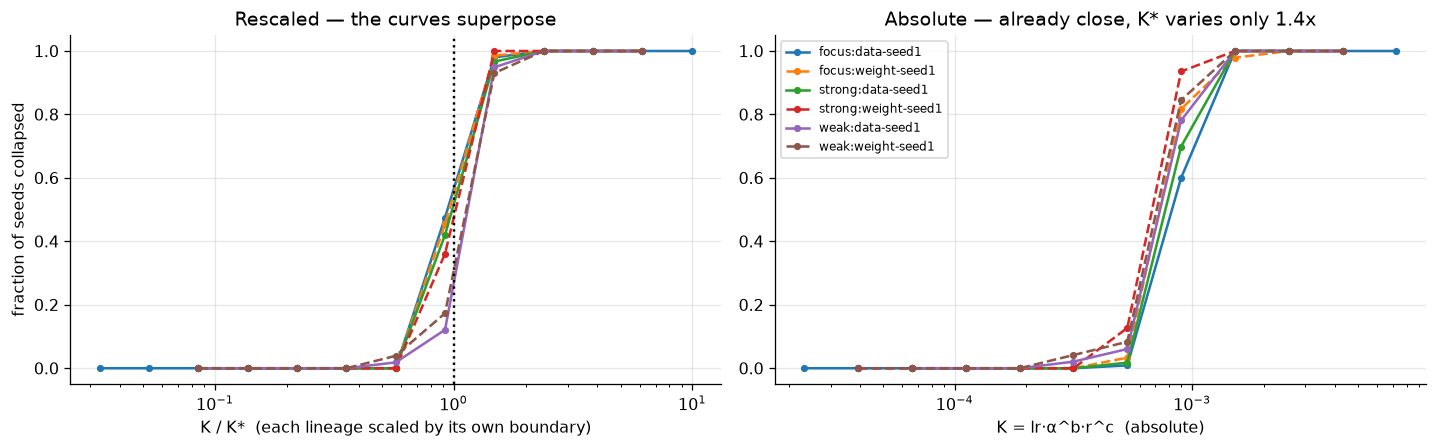

In [9]:
# The money plot: rescale each lineage's K by its own K* and the six collapse curves superpose.
runs["K"] = runs.apply(lambda r: r.lr * r.alpha ** fits[r.lineage].b * r["rank"] ** fits[r.lineage].c, axis=1)
runs["K_rel"] = runs.apply(lambda r: r.K / ks_all[r.lineage]["kstar"], axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.0))
bins = np.logspace(-2, 1.1, 16)
ctr = np.sqrt(bins[:-1] * bins[1:])
for lin in LIN:
    d = runs[runs.lineage.eq(lin)]
    idx = np.digitize(d.K_rel, bins) - 1
    frac = [d.collapsed[idx == i].mean() if (idx == i).sum() >= 5 else np.nan for i in range(len(ctr))]
    axes[0].plot(ctr, frac, STYLE[lin], marker="o", ms=3.5, color=COLOR[lin], label=lin, lw=1.6)
    raw = np.digitize(d.K, np.logspace(-5.2, -1.8, 16)) - 1
    rc = np.sqrt(np.logspace(-5.2, -1.8, 16)[:-1] * np.logspace(-5.2, -1.8, 16)[1:])
    fr = [d.collapsed[raw == i].mean() if (raw == i).sum() >= 5 else np.nan for i in range(len(rc))]
    axes[1].plot(rc, fr, STYLE[lin], marker="o", ms=3.5, color=COLOR[lin], label=lin, lw=1.6)
axes[0].axvline(1, color="k", ls=":", lw=1.5); axes[0].set_xscale("log")
axes[0].set_xlabel("K / K*  (each lineage scaled by its own boundary)")
axes[0].set_ylabel("fraction of seeds collapsed"); axes[0].set_title("Rescaled — the curves superpose")
axes[1].set_xscale("log"); axes[1].set_xlabel("K = lr·α^b·r^c  (absolute)")
axes[1].set_title("Absolute — already close, K* varies only 1.4x")
axes[1].legend(fontsize=7.5, loc="upper left")
fig.tight_layout(); plt.show()

## 5. Rank is protective — without assuming the model

The logistic fit says $c<0$ on every arm, but that conclusion leans on a functional form. Here is
the same claim read straight off the grid: hold $(\mathrm{lr}, \alpha)$ fixed, vary rank, and
compare the collapse fraction of the rank-1/2 cells against the rank-≥8 cells at those exact
coordinates.

In [10]:
cf = runs.groupby(["lineage", "lr", "alpha", "rank"]).collapsed.mean().reset_index(name="frac")
pairs = []
for lin in LIN:
    for (lr, a), g in cf[cf.lineage.eq(lin)].groupby(["lr", "alpha"]):
        lo, hi = g[g["rank"].le(2)].frac, g[g["rank"].ge(8)].frac
        if len(lo) and len(hi):
            pairs.append(dict(lineage=lin, lr=lr, alpha=a, low_rank=lo.mean(), high_rank=hi.mean()))
pairs = pd.DataFrame(pairs)
display(pairs.groupby("lineage").agg(slices=("low_rank", "size"), low_rank=("low_rank", "mean"),
                                     high_rank=("high_rank", "mean")).reindex(LIN).round(3))
nz = pairs[pairs.low_rank != pairs.high_rank]
print(f"overall: rank 1-2 collapse {pairs.low_rank.mean():.3f} vs rank>=8 {pairs.high_rank.mean():.3f}")
print(f"low > high in {(pairs.low_rank > pairs.high_rank).sum()}/{len(pairs)} slices, "
      f"low < high in {(pairs.low_rank < pairs.high_rank).sum()}, tied {(pairs.low_rank == pairs.high_rank).sum()}")
print(f"Wilcoxon signed-rank on the {len(nz)} non-tied slices: p = {wilcoxon(nz.low_rank, nz.high_rank).pvalue:.2g}")
print("\nNot one slice reverses the direction -- this is the §12 blind spot closed on every lineage.")

,slices,low_rank,high_rank
lineage,,,
focus:data-seed1,4,0.675,0.112
focus:weight-seed1,3,0.667,0.417
strong:data-seed1,3,0.556,0.250
strong:weight-seed1,3,0.667,0.556
weak:data-seed1,3,0.778,0.250
weak:weight-seed1,3,0.667,0.194


overall: rank 1-2 collapse 0.668 vs rank>=8 0.287
low > high in 14/19 slices, low < high in 0, tied 5
Wilcoxon signed-rank on the 14 non-tied slices: p = 0.00097

Not one slice reverses the direction -- this is the §12 blind spot closed on every lineage.


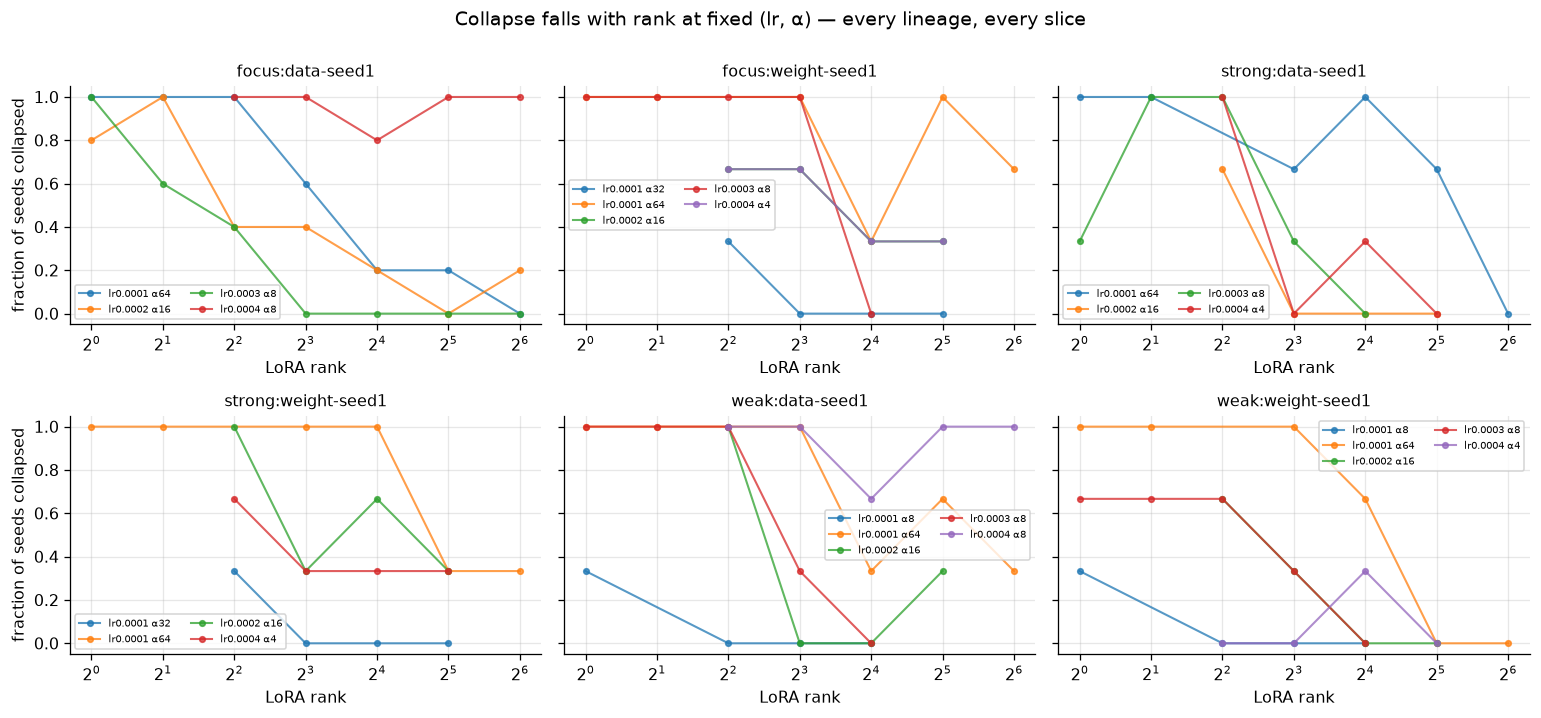

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(13.5, 6.2), sharey=True)
for ax, lin in zip(axes.ravel(), LIN):
    d = cf[cf.lineage.eq(lin)]
    for (lr, a), g in d.groupby(["lr", "alpha"]):
        if g["rank"].nunique() >= 4 and g.frac.std() > 0:
            g = g.sort_values("rank")
            ax.plot(g["rank"], g.frac, marker="o", ms=3.5, lw=1.3, alpha=.75,
                    label=f"lr{lr:g} α{a}")
    ax.set_xscale("log", base=2); ax.set_title(lin, fontsize=10)
    ax.set_xlabel("LoRA rank"); ax.legend(fontsize=6.5, ncol=2)
axes[0, 0].set_ylabel("fraction of seeds collapsed"); axes[1, 0].set_ylabel("fraction of seeds collapsed")
fig.suptitle("Collapse falls with rank at fixed (lr, α) — every lineage, every slice", y=1.0)
fig.tight_layout(); plt.show()

## 6. Signal peaks just below the cliff

The practical question is not only *where* students die but *where they are best*. Among surviving
seeds, mean $p_{dog}$ rises as $K$ approaches $K^{\ast}$ and falls once past it — so the best operating
point is just under the boundary, not far from it.

Pearson(ln K, p_dog) among survivors:
  focus:data-seed1       n= 387   rho = +0.308
  focus:weight-seed1     n= 181   rho = +0.338
  strong:data-seed1      n= 192   rho = +0.194
  strong:weight-seed1    n= 175   rho = +0.304
  weak:data-seed1        n= 193   rho = +0.117
  weak:weight-seed1      n= 194   rho = +0.203

mean p_dog among SURVIVING seeds, by K/K* band:


lineage,focus:data-seed1,focus:weight-seed1,strong:data-seed1,strong:weight-seed1,weak:data-seed1,weak:weight-seed1
band,,,,,,
<0.25,0.0383,0.0170,0.0251,0.0143,0.0165,0.0107
0.25-0.5,0.0746,0.0260,0.0396,0.0216,0.0198,0.0103
0.5-0.75,0.0999,0.0397,0.0372,0.0299,0.0241,0.0129
0.75-1,0.0856,0.0449,0.0362,0.0355,0.0183,0.0135
>1,0.0165,0.0115,0.0325,0.0189,0.0167,0.0130


n survivors per band:


lineage,focus:data-seed1,focus:weight-seed1,strong:data-seed1,strong:weight-seed1,weak:data-seed1,weak:weight-seed1
band,,,,,,
<0.25,95,48,54,45,42,45
0.25-0.5,105,51,51,45,45,44
0.5-0.75,90,48,45,42,44,44
0.75-1,81,27,35,35,38,38
>1,16,7,7,8,24,23


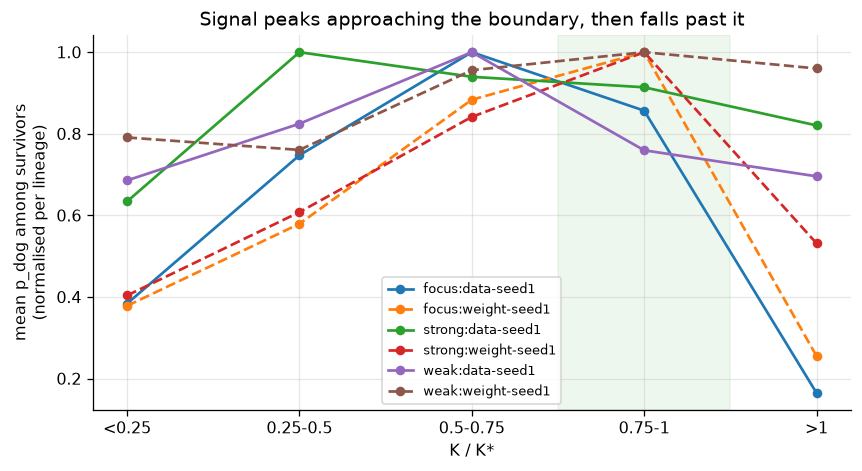

In [12]:
alive = runs[runs.collapsed.eq(0)].copy()
print("Pearson(ln K, p_dog) among survivors:")
for lin in LIN:
    a = alive[alive.lineage.eq(lin)]
    print(f"  {lin:22s} n={len(a):4d}   rho = {np.corrcoef(np.log(a.K), a.test)[0, 1]:+.3f}")

alive["band"] = pd.cut(alive.K_rel, [0, .25, .5, .75, 1.0, 1e9],
                       labels=["<0.25", "0.25-0.5", "0.5-0.75", "0.75-1", ">1"])
mean_tbl = alive.pivot_table(index="band", columns="lineage", values="test",
                             aggfunc="mean", observed=False).reindex(columns=LIN)
n_tbl = alive.pivot_table(index="band", columns="lineage", values="test",
                          aggfunc="size", observed=False).reindex(columns=LIN).fillna(0).astype(int)
print("\nmean p_dog among SURVIVING seeds, by K/K* band:"); display(mean_tbl.round(4))
print("n survivors per band:"); display(n_tbl)

fig, ax = plt.subplots(figsize=(7.6, 4.2))
x = np.arange(len(mean_tbl.index))
for lin in LIN:
    ax.plot(x, mean_tbl[lin] / mean_tbl[lin].max(), STYLE[lin], marker="o", ms=5,
            color=COLOR[lin], label=lin, lw=1.7)
ax.set_xticks(x); ax.set_xticklabels(mean_tbl.index)
ax.set_xlabel("K / K*"); ax.set_ylabel("mean p_dog among survivors\n(normalised per lineage)")
ax.axvspan(2.5, 3.5, color="tab:green", alpha=.08)
ax.set_title("Signal peaks approaching the boundary, then falls past it")
ax.legend(fontsize=8); fig.tight_layout(); plt.show()

## 7. What this costs you in practice

The standard recipe (`lr 1e-4, r8, α32` — the Blank et al. port) is a fixed point in
$(\mathrm{lr}, r, \alpha)$ space, so as $K^{\ast}$ shifts between lineages it lands at a different
place relative to each one's cliff. Below: where it sits, what it scores, and what the best cell
on that arm scores instead.

In [13]:
cm = (runs.groupby(["lineage", "student_tag"])
      .agg(p=("test", "mean"), n=("test", "size"), dead=("collapsed", "sum"),
           K_rel=("K_rel", "first")).reset_index())
std = cm[cm.student_tag.eq("ep20_lr1e-4_r8a32")].set_index("lineage")
best = cm.loc[cm.groupby("lineage").p.idxmax()].set_index("lineage")
compare = pd.DataFrame({
    "std_p": std.p, "std_K/K*": std.K_rel, "std_dead": std.dead.astype(str) + "/" + std.n.astype(str),
    "best_cell": best.student_tag.str.replace("ep20_", "", regex=False),
    "best_p": best.p, "best_K/K*": best.K_rel,
    "best_dead": best.dead.astype(str) + "/" + best.n.astype(str)})
compare["gain"] = (compare.best_p / compare.std_p).round(2)
display(compare.reindex(LIN).round(4))

print("top-3 cells per lineage (cell-mean p_dog):")
for lin in LIN:
    top = cm[cm.lineage.eq(lin)].nlargest(3, "p")
    print(f"  {lin:22s} " + " | ".join(
        f"{r.student_tag.replace('ep20_', '')} p={r.p:.3f} K/K*={r.K_rel:.2f}" for r in top.itertuples()))

,std_p,std_K/K*,std_dead,best_cell,best_p,best_K/K*,best_dead,gain
lineage,,,,,,,,
focus:data-seed1,0.1227,0.6789,0/5,lr4e-4_r32a4,0.2459,0.7434,0/5,2.00
focus:weight-seed1,0.0792,0.7655,0/3,lr1e-4_r8a32,0.0792,0.7655,0/3,1.00
strong:data-seed1,0.0838,0.7240,0/3,lr5e-4_r16a2,0.0857,0.7620,0/3,1.02
strong:weight-seed1,0.0281,0.8150,0/3,lr5e-4_r8a2,0.0726,0.9093,1/3,2.58
weak:data-seed1,0.0124,0.8610,0/3,lr2e-4_r32a8,0.0473,0.6454,0/3,3.82
weak:weight-seed1,0.0117,0.7981,0/3,lr1e-4_r32a32,0.0217,0.6921,0/3,1.87


top-3 cells per lineage (cell-mean p_dog):
  focus:data-seed1       lr4e-4_r32a4 p=0.246 K/K*=0.74 | lr4e-4_r16a4 p=0.172 K/K*=0.79 | lr3e-4_r16a8 p=0.148 K/K*=0.88
  focus:weight-seed1     lr1e-4_r8a32 p=0.079 K/K*=0.77 | lr1e-4_r16a32 p=0.075 K/K*=0.72 | lr1e-4_r4a32 p=0.071 K/K*=0.81
  strong:data-seed1      lr5e-4_r16a2 p=0.086 K/K*=0.76 | lr1e-4_r8a32 p=0.084 K/K*=0.72 | lr1e-4_r16a16 p=0.066 K/K*=0.47
  strong:weight-seed1    lr5e-4_r8a2 p=0.073 K/K*=0.91 | lr2e-4_r32a16 p=0.072 K/K*=0.99 | lr2e-4_r64a8 p=0.054 K/K*=0.63
  weak:data-seed1        lr2e-4_r32a8 p=0.047 K/K*=0.65 | lr2e-4_r16a8 p=0.034 K/K*=0.70 | lr5e-5_r16a64 p=0.029 K/K*=0.59
  weak:weight-seed1      lr1e-4_r32a32 p=0.022 K/K*=0.69 | lr1e-4_r64a64 p=0.022 K/K*=0.93 | lr1e-4_r32a64 p=0.021 K/K*=1.00


Two things to read off this table:

- **The winners all sit at $K/K^{\ast} \approx 0.65$–0.91** — just under the boundary, exactly as §5 of
  the original analysis predicted, and now confirmed on five new lineages.
- **The standard recipe is not uniformly safe.** It survives everywhere at this threshold, but on
  the `weak` arms it sits at $K/K^{\ast}\approx0.80$–0.86 with markedly worse yield than a gentler,
  higher-rank cell. `weak:data-seed1` gains **3.8×** by moving to `lr2e-4_r32a8` at $K/K^{\ast}=0.65$.

## 8. Robustness — threshold, and why 0.01 broke

Every claim above rests on the binary collapse label, so here is the full sweep. The exponents are
flat across $5\times10^{-4}$–$5\times10^{-3}$; at 0.01 the weaker arms' estimates start to run, and
by 0.02 they are meaningless (the cut is deep inside their live mode).

,threshold,dead_frac,b·focus:data,b·focus:weight,b·strong:data,b·strong:weight,b·weak:data,b·weak:weight,p_homog_b
0,0.0005,0.365,0.56,0.56,0.58,0.52,0.60,0.57,0.0006
1,0.0010,0.378,0.56,0.56,0.57,0.52,0.59,0.57,0.0017
2,0.0020,0.398,0.56,0.55,0.55,0.54,0.60,0.58,0.0008
3,0.0050,0.426,0.57,0.56,0.55,0.54,0.58,0.53,0.4045
4,0.0100,0.489,0.57,0.56,0.51,0.62,0.66,0.43,0.0012
5,0.0200,0.673,0.56,0.30,0.55,0.51,0.59,-1.57,0.5564


,threshold,dead_frac,c·focus:data,c·focus:weight,c·strong:data,c·strong:weight,c·weak:data,c·weak:weight,p_homog_c
0,0.0005,0.365,-0.08,-0.08,-0.05,-0.04,-0.06,-0.07,0.1797
1,0.0010,0.378,-0.09,-0.09,-0.04,-0.04,-0.07,-0.06,0.0707
2,0.0020,0.398,-0.08,-0.10,-0.04,-0.09,-0.07,-0.06,0.1070
3,0.0050,0.426,-0.08,-0.08,-0.07,-0.09,-0.13,-0.10,0.8207
4,0.0100,0.489,-0.09,-0.12,-0.06,-0.16,-0.24,-0.44,0.0005
5,0.0200,0.673,-0.08,-0.78,-0.26,-1.23,-1.54,-4.01,0.0008


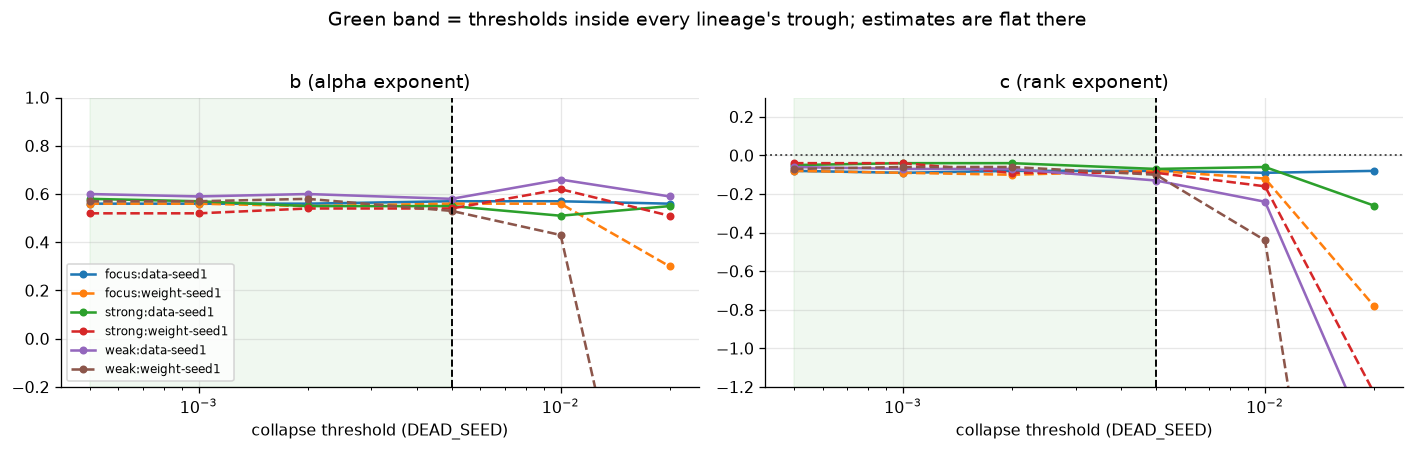

In [14]:
sens = []
for t in (5e-4, 1e-3, 2e-3, 5e-3, 1e-2, 2e-2):
    r = cl.label_collapse(runs_raw, dead_seed=t)
    row = {"threshold": t, "dead_frac": round(r.collapsed.mean(), 3)}
    bs, cs, bc, cc = [], [], [], []
    for lin in LIN:
        f = cl.fit_collapse_law(r[r.lineage.eq(lin)])
        bs.append(f.b); cs.append(f.c); bc.append(f.b_ci); cc.append(f.c_ci)
        row[f"b·{SHORT[lin]}"] = round(f.b, 2)
        row[f"c·{SHORT[lin]}"] = round(f.c, 2)
    se = (np.array(bc)[:, 1] - np.array(bc)[:, 0]) / (2 * 1.96); w = 1 / se ** 2
    Qb = (w * (np.array(bs) - (np.array(bs) * w).sum() / w.sum()) ** 2).sum()
    se = (np.array(cc)[:, 1] - np.array(cc)[:, 0]) / (2 * 1.96); w = 1 / se ** 2
    Qc = (w * (np.array(cs) - (np.array(cs) * w).sum() / w.sum()) ** 2).sum()
    row["p_homog_b"] = round(1 - chi2.cdf(Qb, 5), 4)
    row["p_homog_c"] = round(1 - chi2.cdf(Qc, 5), 4)
    sens.append(row)
sens = pd.DataFrame(sens)
display(sens[["threshold", "dead_frac"] + [c for c in sens if c.startswith("b·")] + ["p_homog_b"]])
display(sens[["threshold", "dead_frac"] + [c for c in sens if c.startswith("c·")] + ["p_homog_c"]])

fig, axes = plt.subplots(1, 2, figsize=(12.4, 3.8))
for ax, key, ttl in [(axes[0], "b·", "b (alpha exponent)"), (axes[1], "c·", "c (rank exponent)")]:
    for lin in LIN:
        ax.plot(sens.threshold, sens[f"{key}{SHORT[lin]}"], STYLE[lin], marker="o", ms=4,
                color=COLOR[lin], label=lin, lw=1.6)
    ax.set_xscale("log"); ax.axvline(0.005, color="k", ls="--", lw=1.2)
    ax.axvspan(5e-4, 5e-3, color="tab:green", alpha=.07)
    ax.set_xlabel("collapse threshold (DEAD_SEED)"); ax.set_title(ttl)
axes[0].set_ylim(-0.2, 1.0); axes[1].set_ylim(-1.2, 0.3)
axes[1].axhline(0, color="0.3", ls=":", lw=1.2)
axes[0].legend(fontsize=7.5, loc="lower left")
fig.suptitle("Green band = thresholds inside every lineage's trough; estimates are flat there", y=1.02)
fig.tight_layout(); plt.show()

### Why this is a real methodological finding, not bookkeeping

Reusing §12's `0.01` on the five new arms would have produced a confident and **wrong** headline.
At 0.01 the six arms look genuinely different — $I^2 = 75\%$ for $b$ and $78\%$ for $c$
($p = 0.0012$ / $0.00047$), $b$ spanning 0.43–0.66, $c$ spanning −0.06 to −0.44, and $K^{\ast}$
spanning **6.3×**. Every one of those numbers is an artefact of a threshold that cuts through the
weaker lineages' live mode. The lesson generalises the §12 leverage lesson: *check that an
inherited analysis constant is still valid on the new data before reusing it* — a label definition
tuned on one signal scale does not transfer to lineages with a different one.

In [15]:
# The counterfactual, explicitly: same code, inherited threshold.
r01 = cl.label_collapse(runs_raw, dead_seed=0.01)
alt = []
for lin in LIN:
    f = cl.fit_collapse_law(r01[r01.lineage.eq(lin)])
    ks = cl.estimate_kstar(r01[r01.lineage.eq(lin)], f.b, f.c)
    alt.append(dict(lineage=lin, b=round(f.b, 3), c=round(f.c, 3), Kstar=f"{ks['kstar']:.2e}"))
alt = pd.DataFrame(alt)
print("AT THE INHERITED THRESHOLD 0.01 (what we would have reported):")
display(alt)
kk = [float(a) for a in alt.Kstar]
print(f"  K* spread {max(kk)/min(kk):.1f}x   b spread [{alt.b.min()}, {alt.b.max()}]   "
      f"c spread [{alt.c.min()}, {alt.c.max()}]")
print("\nAT 0.005 (reported above): K* spread 1.4x, b [0.530, 0.581], c [-0.127, -0.068], I^2 = 2%/0%.")

AT THE INHERITED THRESHOLD 0.01 (what we would have reported):


,lineage,b,c,Kstar
0,focus:data-seed1,0.573,-0.092,8.13e-04
1,focus:weight-seed1,0.557,-0.118,5.03e-04
2,strong:data-seed1,0.508,-0.062,6.95e-04
3,strong:weight-seed1,0.622,-0.165,4.73e-04
4,weak:data-seed1,0.661,-0.236,5.06e-04
5,weak:weight-seed1,0.430,-0.441,1.29e-04


  K* spread 6.3x   b spread [0.43, 0.661]   c spread [-0.441, -0.062]

AT 0.005 (reported above): K* spread 1.4x, b [0.530, 0.581], c [-0.127, -0.068], I^2 = 2%/0%.


## 9. Mechanism check — the coherence assumption, measured on trained adapters

Everything above treats the law as an empirical regularity. The mechanistic account of *why* it
takes the form $\mathrm{lr}\cdot\alpha^{b}\cdot r^{c}$ (notebook
`cross_model_student_hp_exploration`, §12 discussion) rests on three ingredients:

1. **Adam scale-invariance** — per-entry steps are $\approx \pm\mathrm{lr}$ regardless of gradient
   magnitude, so the forward scale $s=\alpha/r$ cancels out of the *adapter's own* update dynamics.
2. **Bilinear growth** — $B$ starts at zero, so $\Delta W = s\,B\!A$ grows like
   $\mathrm{lr}\cdot t\cdot(\sigma + \mathrm{lr}\cdot t)$, whose late $(\mathrm{lr}\,t)^2$ term is
   what turns $\alpha$ into $\sqrt{\alpha}$ at the boundary.
3. **Coherence** — the $r$ rank-1 channels $b_k a_k^{\top}$ that sum to $B\!A$ mostly *add* rather
   than cancel.

Ingredient 3 is the load-bearing one for **rank**, and until now it was assumed from the
literature rather than measured. It decides whether the explicit $1/r$ in $s=\alpha/r$ survives
into the applied perturbation $s\,\lVert\sum_k b_k a_k^{\top}\rVert$:

- **iid channels** (the model rsLoRA is derived from; Kalajdzievski 2023, arXiv:2312.03732): the
  sum grows like $\sqrt{r}$, only partially cancelling the $1/r$ — predicting $c=-0.25$ and an
  update energy spread over $\sim r$ directions.
- **coherent channels** (Hu et al. 2021, arXiv:2106.09685 §7: $\Delta W$ has very low intrinsic
  rank regardless of $r$): the sum grows like $r$, cancelling the $1/r$ *exactly* — predicting
  $c=0$, **absolute $\alpha$** in the law, and update energy concentrated in $O(1)$ directions no
  matter the nominal rank.

Every lineage here measures $c\approx-0.09$ — much nearer the coherent endpoint. And there is a
mechanistic reason to *expect* alignment: every column of $B$ receives a gradient proportional to
the **same** output-error direction $\delta$ ($\nabla_B = s\,\delta(Ax)^{\top}$), so all $r$
channels are pulled toward a shared direction from step one.

The cell below checks this directly on trained checkpoints — four `focus:data-seed1` adapters
(`ftseed1`) spanning an 8× range of nominal rank and the aggression axis: the std recipe
`r8α32@lr1e-4`, a rank-64 cell `r64α64@lr1e-4`, and two aggressive low-α rank-32 cells —
`r32α4@lr2e-4` (mean p 0.089) and the grid winner `r32α4@lr4e-4` (best transfer on the whole
grid, mean p 0.246, sitting just under the cliff at `lr5e-4`).
For each of the 48 LoRA module pairs (4 GPT-NeoX target modules × 12 layers) it computes, then
averages over modules:

- **stable rank of $B\!A$** $= \lVert B\!A\rVert_F^2/\sigma_1^2$ — the effective number of
  directions the update energy occupies. This is the discriminating statistic: **iid ⇒ $\approx r$;
  coherent ⇒ $O(1)$, flat in $r$.**
- **top-1 energy** $= \sigma_1^2/\lVert B\!A\rVert_F^2$ — fraction of the update in the single
  largest singular direction.
- **mean pairwise $\lvert\cos\rvert$ between columns of $B$** — direct alignment of the $r$ output
  directions. Random vectors in $d=768$ dims give $\sqrt{2/(\pi\cdot768)}\approx0.03$.

**Why it matters.** If stable rank tracks $r$, the coherent-sum step of the derivation is wrong and
the measured $c\approx-0.09$ needs another explanation. If it stays $O(1)$ across an 8× change in
nominal rank, then the "absolute $\alpha$, weakly protective rank" structure of the law has a
*measured* mechanism behind it — and §6's observation that extra rank helps at fixed risk gets a
natural reading: aligned extra channels don't enlarge the perturbation, they buy a cleaner estimate
of one shared direction (the steering-vector picture of Blank et al.). Scope: one lineage, one ft
seed, alive cells only — dead-run adapters are a separate (interesting) question.


In [16]:
# The measurement: raw safetensors -> per-module SVD of B@A. No model load, no GPU.
family, tag, base = cl.LAW_LINEAGES[0]                       # focus:data-seed1
lineage_dir = (OUTPUT_ROOT / "students/dog" / base
               / f"from_{tag}_tseed1_nbase-pythia-160m/ex10-20_prefix_n100k")
COHER_TAGS = ["ep20_lr1e-4_r8a32", "ep20_lr1e-4_r64a64",
              "ep20_lr2e-4_r32a4", "ep20_lr4e-4_r32a4"]

RAND_COS = float(np.sqrt(2 / (np.pi * 768)))   # random-direction |cos| baseline at d=768
mods = {t: cl.adapter_coherence(lineage_dir / t / "ftseed1/checkpoints/adapter_model.safetensors")
        for t in COHER_TAGS}

ref = cells[cells.lineage.eq("focus:data-seed1")].set_index("student_tag").mean_test
tab = pd.DataFrame({t: {
    "r": int(df["rank"].iloc[0]),
    "stable rank of B·A": df.stable_rank.mean(),
    "module max": df.stable_rank.max(),
    "top-1 energy": df.top1_energy.mean(),
    "|cos| B cols": df.b_col_cos.mean(),
    "× random": df.b_col_cos.mean() / RAND_COS,
    "cell mean p": ref.get(t, np.nan),
} for t, df in mods.items()}).T
print(f"{len(next(iter(mods.values())))} LoRA module pairs per adapter; "
      f"random |cos| baseline {RAND_COS:.3f}")
display(tab.round(2))

# Data-driven verdict -- no hard-coded conclusion.
sr = {t: df.stable_rank.mean() for t, df in mods.items()}
frac_of_nominal = {t: sr[t] / df["rank"].iloc[0] for t, df in mods.items()}
growth = sr["ep20_lr1e-4_r64a64"] / sr["ep20_lr1e-4_r8a32"]
print(f"\n8x more nominal channels bought {growth:.2f}x more effective directions "
      f"(iid channels predict ~8x).")
if max(frac_of_nominal.values()) < 0.5 and growth < 4:
    print("VERDICT: stable rank is O(1) and nearly flat in r -> the rank-sum is COHERENT. "
          "The 1/r in s=alpha/r cancels against the ~r-fold aligned sum, so absolute alpha "
          "belongs in the law, and rank survives only as the weak protective exponent "
          "(c ~ -0.09, near the coherent endpoint 0, far from the iid -0.25).")
elif min(frac_of_nominal.values()) > 0.5:
    print("VERDICT: stable rank tracks nominal rank -> channels are largely INDEPENDENT; "
          "the coherent-sum step of the mechanism is falsified on these checkpoints and "
          "c ~ -0.09 needs another explanation.")
else:
    print("VERDICT: mixed -- coherence differs across adapters; inspect per-module rows "
          "before leaning on the coherent-sum step.")


48 LoRA module pairs per adapter; random |cos| baseline 0.029


,r,stable rank of B·A,module max,top-1 energy,|cos| B cols,× random,cell mean p
ep20_lr1e-4_r8a32,8.0,2.85,4.52,0.40,0.24,8.47,0.12
ep20_lr1e-4_r64a64,64.0,3.61,7.29,0.34,0.21,7.36,0.08
ep20_lr2e-4_r32a4,32.0,1.48,2.97,0.73,0.46,15.98,0.09
ep20_lr4e-4_r32a4,32.0,1.61,2.46,0.68,0.40,13.97,0.25



8x more nominal channels bought 1.27x more effective directions (iid channels predict ~8x).
VERDICT: stable rank is O(1) and nearly flat in r -> the rank-sum is COHERENT. The 1/r in s=alpha/r cancels against the ~r-fold aligned sum, so absolute alpha belongs in the law, and rank survives only as the weak protective exponent (c ~ -0.09, near the coherent endpoint 0, far from the iid -0.25).


## 10. Interpretation and limits

**What the campaign establishes.**

- The collapse boundary $K = \mathrm{lr}\cdot\alpha^{b}\cdot r^{c} \ge K^{\ast}$ is **not an artefact of
  one teacher/student pair**. Three teacher recipes — including one (`weak`) trained with a
  4× lower LR for 3.5× more epochs — and two different student initialisations all give
  $b \approx 0.56$, $c \approx -0.085$, $K^{\ast} \approx 6\text{–}9\times10^{-4}$.
- **Rank belongs in the law on every lineage.** $c<0$ with intervals excluding zero in 6/6, and the
  model-free rank comparison never reverses. §11's "rank-free" law is dead on all six lineages,
  not just the one it was refuted on.
- $\alpha$'s exponent is **near but not equal to $\tfrac12$** (pooled 0.561, CI excludes 0.5 on
  the tightest arms), so $\mathrm{lr}\cdot\sqrt{\alpha}$ remains a good working approximation and
  $\mathrm{lr}\cdot\alpha$ (§8) remains wrong.

**What it does not establish.**

- **One animal, one model size, one pool.** Everything here is `dog` on pythia-160m with the
  `ex10-20_prefix_n100k` number pool. The exponents may well be architecture- or scale-dependent.
- **ep20 only.** §12 found $K^{\ast}$ moves weakly with epochs ($\propto \text{epochs}^{-0.2}$); this
  campaign did not re-test that across lineages.
- **Teacher trait strength is nearly constant here.** All three teachers sit at $p_{dog}\ge0.97$ on
  their own `favorite` set (focus/strong 0.9997, weak 0.9732), so this design varies the teacher
  *recipe* but barely varies teacher *quality* — it cannot say how $K^{\ast}$ responds to a genuinely
  weak teacher.
- **Absolute transfer differs enormously even where the law agrees.** The best cell reaches
  $p_{dog}=0.246$ on `focus:data-seed1` but only $0.022$ on `weak:weight-seed1` — an 11× spread in
  *yield* sitting on top of a boundary that moves only 1.4×. The law predicts *where the cliff is*,
  not *how much signal you get*.

**Operating rule (updated).** Target $K/K^{\ast} \approx 0.7$–0.9: buy aggressiveness through lr, pay
it back in low $\alpha$, and prefer higher rank — it is protective on every lineage measured. But
**measure $K^{\ast}$ on your own lineage first**; a handful of cells bracketing the boundary is enough,
and the alternative is a fixed recipe that lands anywhere from comfortably safe to past the edge.

**Next.** The clean discriminator for the mechanism is still unrun: train-loss curves of dead vs
alive runs. A near-dose-independent $K^{\ast}$ ($\propto\text{epochs}^{-0.2}$) points at an early
per-step instability — catapult-style basin exit — rather than slow cumulative drift, and the loss
traces would separate those directly.